<a href="https://colab.research.google.com/github/DinaraAntropova/-2/blob/main/%D0%9F%D1%80%D0%B0%D0%BA%D1%82%D0%B8%D1%87%D0%BD%D0%B0_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import pandas as pd
from google.colab import files

uploaded = files.upload()

df = pd.read_csv("bank-full.csv", sep=";")

print(df.shape)
df.head()


Saving bank-full.csv to bank-full.csv
(45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [2]:

# Інформація про структуру датасету
print("Інформація про датасет:")
df.info()

# Статистичні характеристики числових даних
print("\nСтатистичні характеристики:")
display(df.describe())


Інформація про датасет:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB

Статистичні характеристики:


,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [3]:

# Перевірка пропущених значень
print("Пропущені значення:")
print(df.isnull().sum())

# Перевірка дублікатів
print("\nКількість дублікатів:")
print(df.duplicated().sum())

# Перевірка невідомих значень
print("\nКількість значень unknown:")
print((df == "unknown").sum())


Пропущені значення:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

Кількість дублікатів:
0

Кількість значень unknown:
age              0
job            288
marital          0
education     1857
default          0
balance          0
housing          0
loan             0
contact      13020
day              0
month            0
duration         0
campaign         0
pdays            0
previous         0
poutcome     36959
y                0
dtype: int64


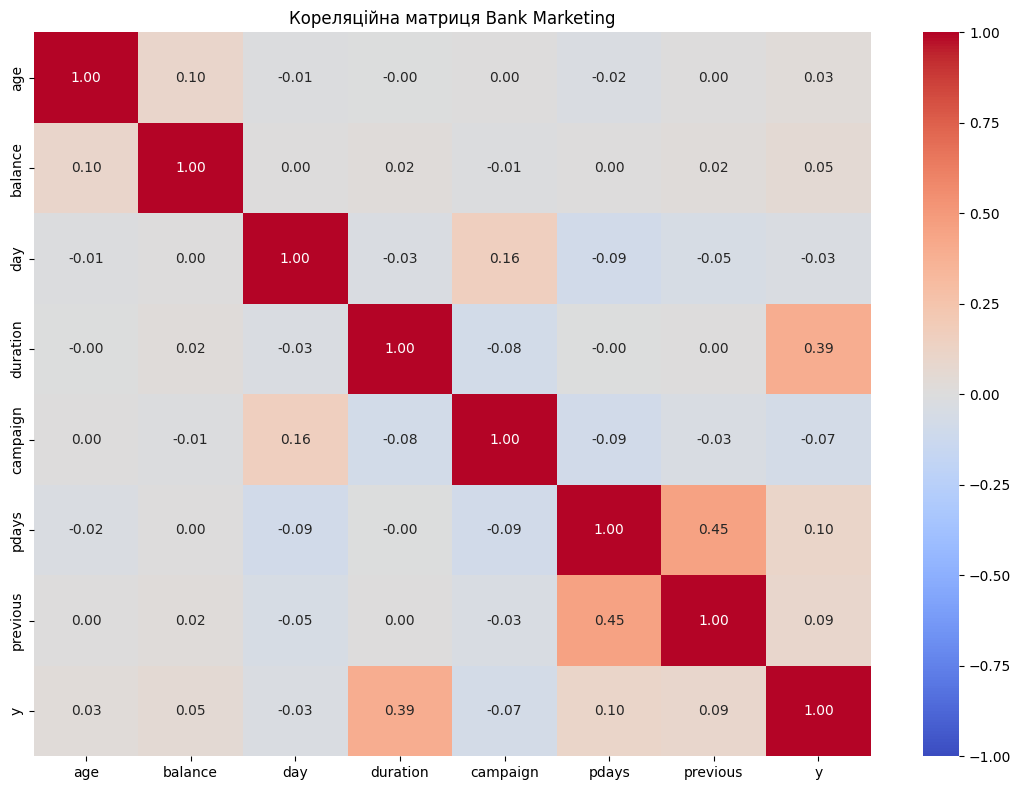

In [4]:

import matplotlib.pyplot as plt
import seaborn as sns

# Вибираємо числові стовпці
df_corr = df.select_dtypes(include="number").copy()

# Перетворюємо цільову змінну на числа
df_corr["y"] = df["y"].map({"no": 0, "yes": 1})

# Будуємо кореляційну матрицю
plt.figure(figsize=(11, 8))

sns.heatmap(
    df_corr.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Кореляційна матриця Bank Marketing")
plt.tight_layout()
plt.show()


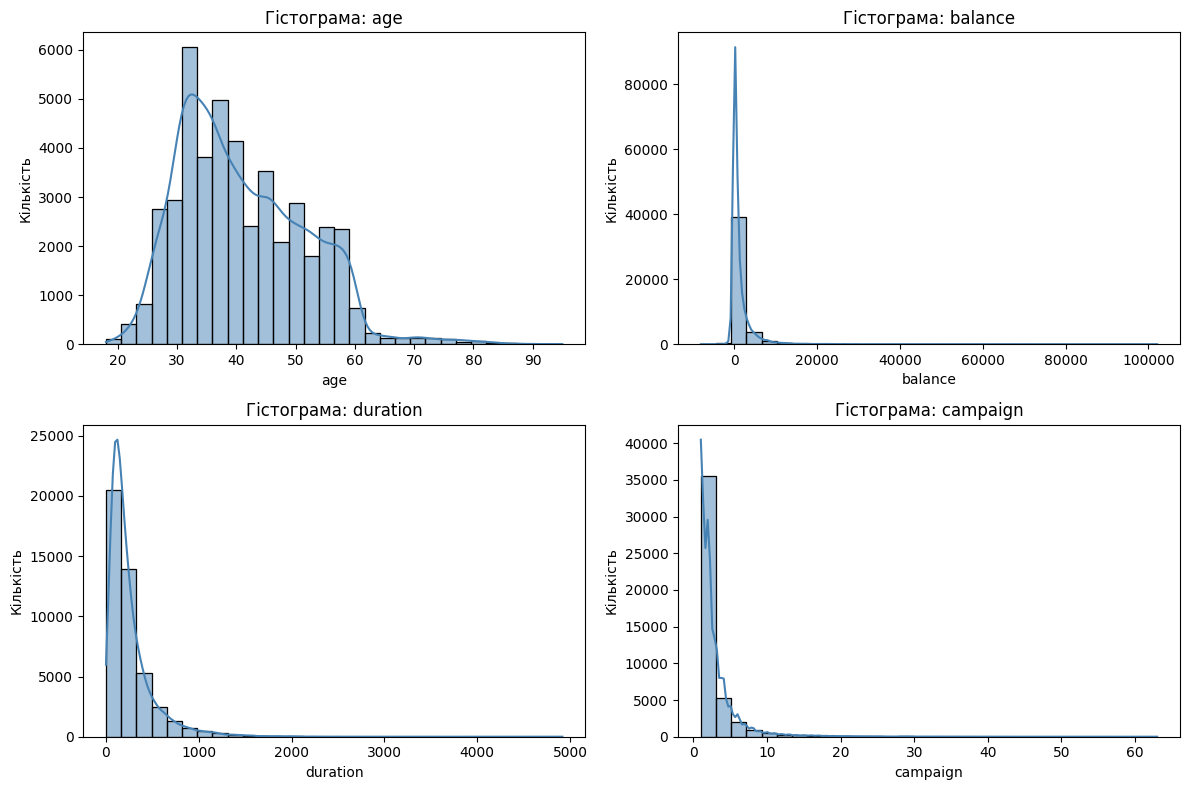

In [5]:

# Побудова гістограм числових ознак

features = ["age", "balance", "duration", "campaign"]

plt.figure(figsize=(12, 8))

for i, feature in enumerate(features):
    plt.subplot(2, 2, i + 1)

    sns.histplot(
        df[feature],
        bins=30,
        kde=True,
        color="steelblue"
    )

    plt.title(f"Гістограма: {feature}")
    plt.xlabel(feature)
    plt.ylabel("Кількість")

plt.tight_layout()
plt.show()


Кількість клієнтів за категоріями:
y
no     39922
yes     5289
Name: count, dtype: int64

Відсотковий розподіл:
y
no     88.30152
yes    11.69848
Name: proportion, dtype: float64


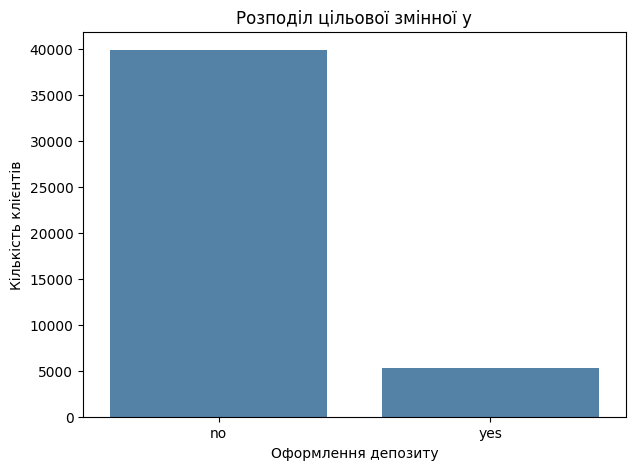

In [6]:

# Аналіз цільової змінної y

print("Кількість клієнтів за категоріями:")
print(df["y"].value_counts())

print("\nВідсотковий розподіл:")
print(df["y"].value_counts(normalize=True) * 100)

# Побудова графіка
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="y",
    order=["no", "yes"],
    color="steelblue"
)

plt.title("Розподіл цільової змінної y")
plt.xlabel("Оформлення депозиту")
plt.ylabel("Кількість клієнтів")

plt.show()


In [8]:

# Створюємо копію датасету
df_clean = df.copy()

# Перетворюємо цільову змінну
df_clean["y"] = df_clean["y"].map({
    "no": 0,
    "yes": 1
})

# Визначаємо вхідні ознаки
X = df_clean.drop(columns=["y", "duration"])

# Визначаємо цільову змінну
y = df_clean["y"]

# Перевіряємо результат
print("Розмір вхідних даних:", X.shape)
print("Розмір цільової змінної:", y.shape)

print("\nТипи вхідних ознак:")
print(X.dtypes)

print("\nЦільова змінна:")
print(y.value_counts())



Розмір вхідних даних: (45211, 15)
Розмір цільової змінної: (45211,)

Типи вхідних ознак:
age           int64
job          object
marital      object
education    object
default      object
balance       int64
housing      object
loan         object
contact      object
day           int64
month        object
campaign      int64
pdays         int64
previous      int64
poutcome     object
dtype: object

Цільова змінна:
y
0    39922
1     5289
Name: count, dtype: int64


In [9]:

from sklearn.model_selection import train_test_split

# Розділення даних на навчальну та тестову вибірки
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Навчальна вибірка:", X_train.shape)
print("Тестова вибірка:", X_test.shape)

print("\nЧастка клієнтів з депозитом:")
print("Навчальна:", round(y_train.mean() * 100, 2), "%")
print("Тестова:", round(y_test.mean() * 100, 2), "%")


Навчальна вибірка: (36168, 15)
Тестова вибірка: (9043, 15)

Частка клієнтів з депозитом:
Навчальна: 11.7 %
Тестова: 11.7 %


In [11]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Визначаємо категоріальні та числові ознаки
categorical_cols = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

numeric_cols = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

# Створюємо перетворювач даних
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
        ("num", "passthrough", numeric_cols)
    ]
)

# Кодуємо навчальні дані
X_train_encoded = preprocessor.fit_transform(X_train)

# Кодуємо тестові дані
X_test_encoded = preprocessor.transform(X_test)

# Перевіряємо результати
print("Категоріальні ознаки:", len(categorical_cols))
print("Числові ознаки:", len(numeric_cols))

print("\nНавчальна вибірка:", X_train_encoded.shape)
print("Тестова вибірка:", X_test_encoded.shape)


Категоріальні ознаки: 9
Числові ознаки: 6

Навчальна вибірка: (36168, 50)
Тестова вибірка: (9043, 50)


In [12]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Створення моделі дерева рішень
tree_model = DecisionTreeClassifier(
    max_depth=5,
    min_samples_leaf=30,
    class_weight="balanced",
    random_state=42
)

# Навчання моделі
tree_model.fit(X_train_encoded, y_train)

# Прогнозування на тестових даних
y_pred_tree = tree_model.predict(X_test_encoded)

# Оцінка якості моделі
print("Модель: Decision Tree")

print("Точність на навчальних даних:",
      accuracy_score(y_train,
      tree_model.predict(X_train_encoded)))

print("Точність на тестових даних:",
      accuracy_score(y_test, y_pred_tree))

print("\nЗвіт про класифікацію:")
print(classification_report(y_test, y_pred_tree,
                            zero_division=0))

print("\nМатриця помилок:")
print(confusion_matrix(y_test, y_pred_tree))


Модель: Decision Tree
Точність на навчальних даних: 0.7990212342402123
Точність на тестових даних: 0.7950901249585315

Звіт про класифікацію:
              precision    recall  f1-score   support

           0       0.93      0.83      0.88      7985
           1       0.30      0.56      0.39      1058

    accuracy                           0.80      9043
   macro avg       0.62      0.69      0.63      9043
weighted avg       0.86      0.80      0.82      9043


Матриця помилок:
[[6596 1389]
 [ 464  594]]


In [13]:

from sklearn.ensemble import RandomForestClassifier

# Створення моделі Random Forest
forest_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=10,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

# Навчання моделі
forest_model.fit(X_train_encoded, y_train)

# Прогнозування на тестових даних
y_pred_forest = forest_model.predict(X_test_encoded)

# Оцінка якості моделі
print("Модель: Random Forest")

print("Точність на навчальних даних:",
      accuracy_score(y_train,
      forest_model.predict(X_train_encoded)))

print("Точність на тестових даних:",
      accuracy_score(y_test, y_pred_forest))

print("\nЗвіт про класифікацію:")
print(classification_report(
    y_test,
    y_pred_forest,
    zero_division=0
))

print("\nМатриця помилок:")
print(confusion_matrix(y_test, y_pred_forest))


Модель: Random Forest
Точність на навчальних даних: 0.832863304578633
Точність на тестових даних: 0.8210770761915294

Звіт про класифікацію:
              precision    recall  f1-score   support

           0       0.94      0.85      0.89      7985
           1       0.35      0.61      0.44      1058

    accuracy                           0.82      9043
   macro avg       0.65      0.73      0.67      9043
weighted avg       0.87      0.82      0.84      9043


Матриця помилок:
[[6778 1207]
 [ 411  647]]


,Модель,Accuracy,Precision,Recall,F1-score
0,Decision Tree,0.795,0.300,0.561,0.391
1,Random Forest,0.821,0.349,0.612,0.444


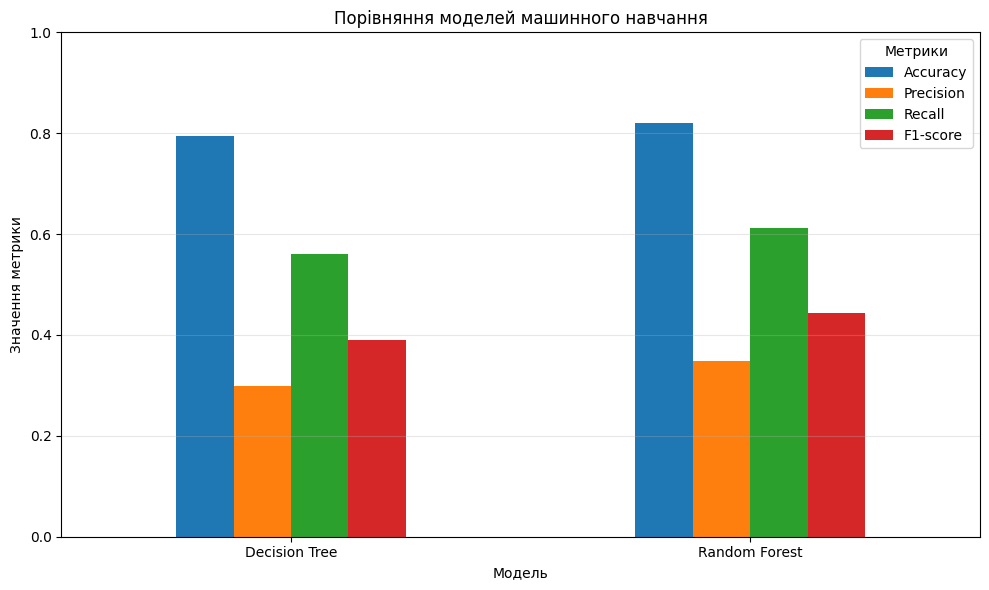

In [14]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Формуємо таблицю результатів
results = pd.DataFrame({
    "Модель": ["Decision Tree", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_tree),
        accuracy_score(y_test, y_pred_forest)
    ],
    "Precision": [
        precision_score(y_test, y_pred_tree),
        precision_score(y_test, y_pred_forest)
    ],
    "Recall": [
        recall_score(y_test, y_pred_tree),
        recall_score(y_test, y_pred_forest)
    ],
    "F1-score": [
        f1_score(y_test, y_pred_tree),
        f1_score(y_test, y_pred_forest)
    ]
})

# Виводимо таблицю
display(results.round(3))

# Будуємо порівняльну діаграму
results.set_index("Модель").plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Порівняння моделей машинного навчання")
plt.ylabel("Значення метрики")
plt.xlabel("Модель")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Метрики")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


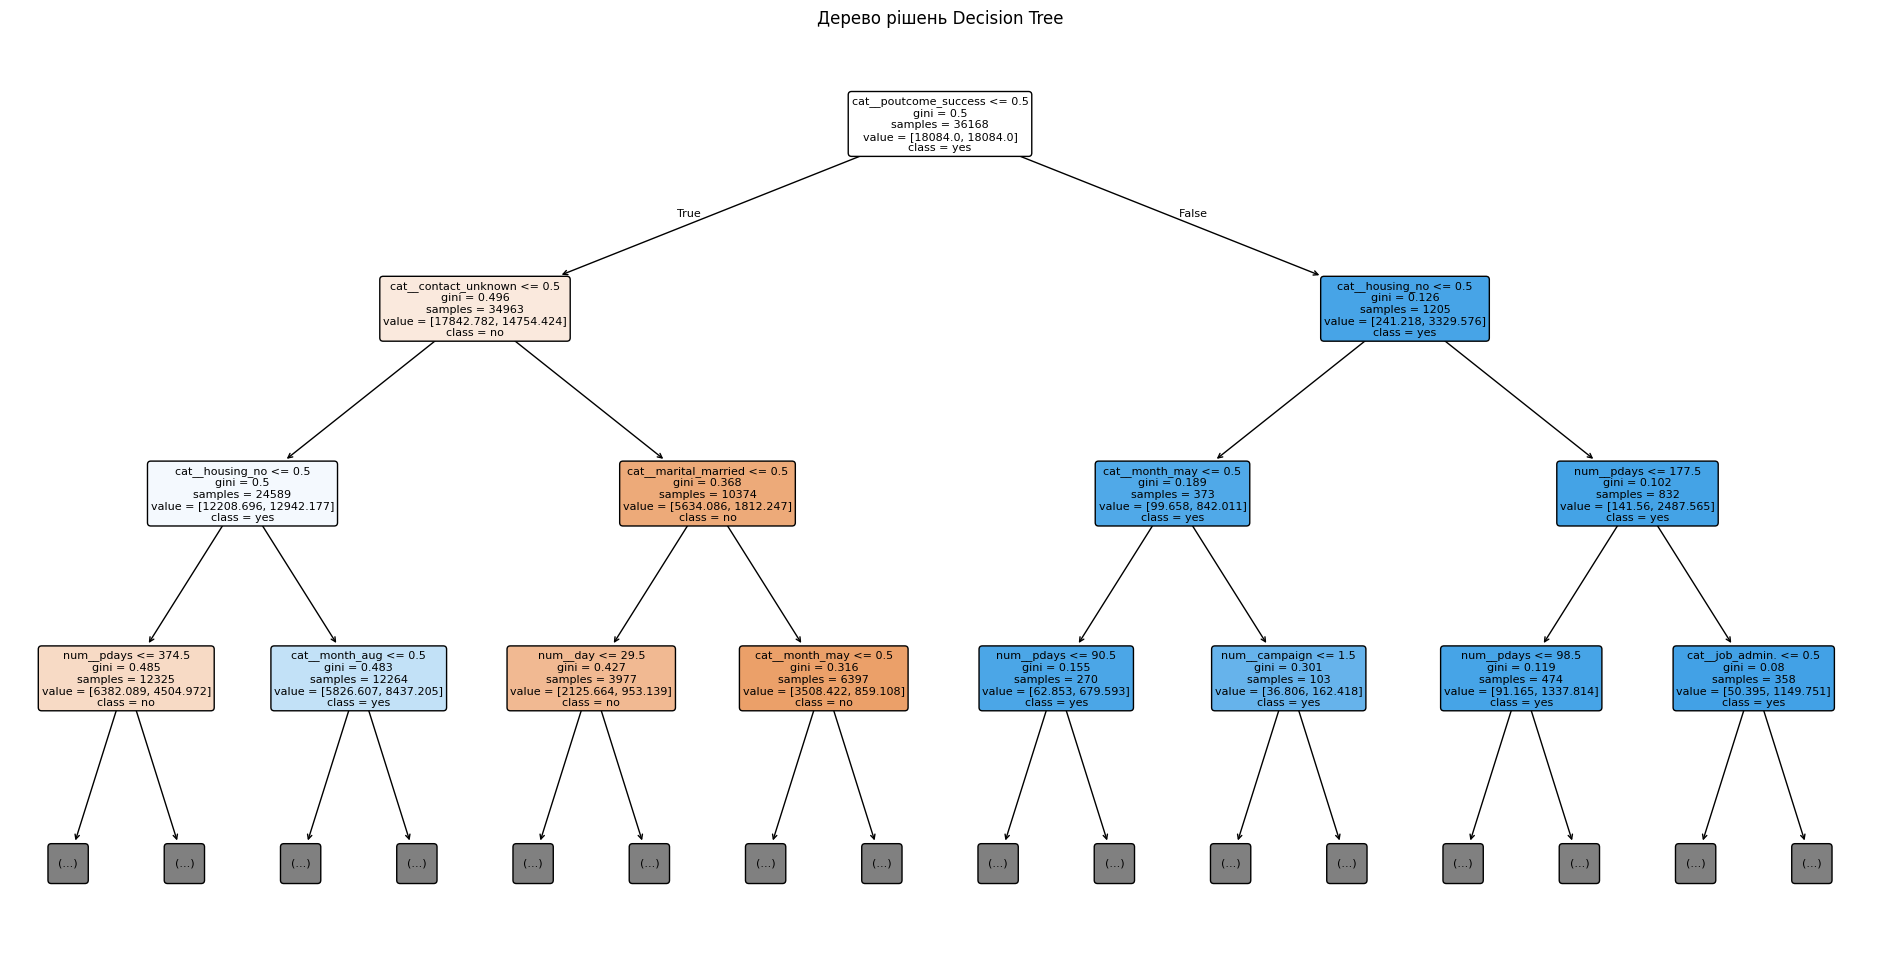

In [15]:

from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

# Отримуємо назви ознак після кодування
feature_names = preprocessor.get_feature_names_out()

# Створюємо графік дерева рішень
plt.figure(figsize=(24, 12))

plot_tree(
    tree_model,
    feature_names=feature_names,
    class_names=["no", "yes"],
    filled=True,
    rounded=True,
    fontsize=8,
    max_depth=3
)

plt.title("Дерево рішень Decision Tree")

# Зберігаємо графік для звіту
plt.savefig(
    "decision_tree.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


,Ознака,Важливість
42,cat__poutcome_success,0.126507
44,num__age,0.079547
27,cat__contact_unknown,0.076716
45,num__balance,0.071442
48,num__pdays,0.057536
46,num__day,0.054420
25,cat__contact_cellular,0.050373
21,cat__housing_no,0.049890
49,num__previous,0.046114
22,cat__housing_yes,0.043508


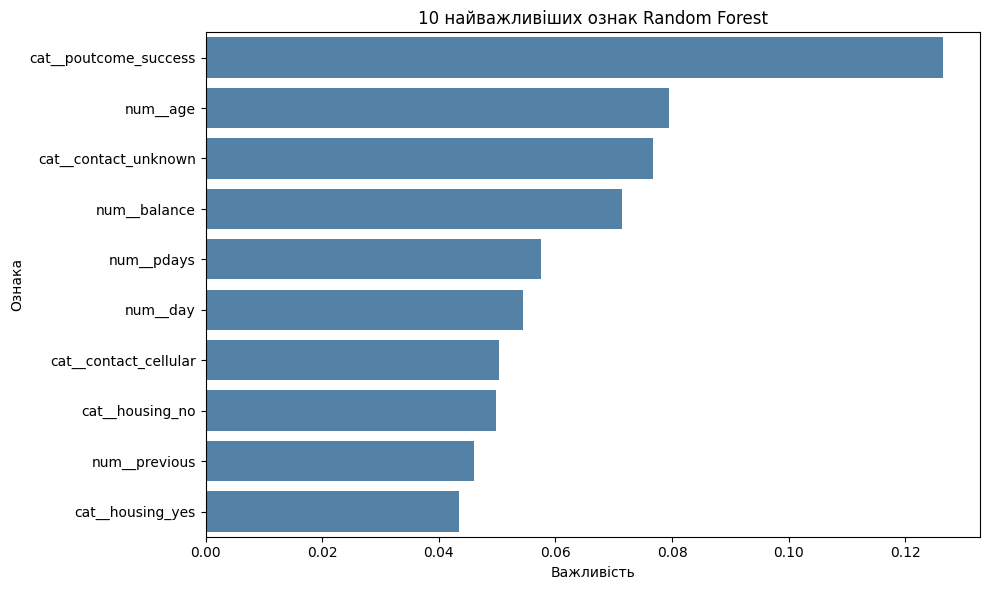

In [16]:

# Отримуємо важливість ознак Random Forest
importances = forest_model.feature_importances_

# Створюємо таблицю
feature_importance = pd.DataFrame({
    "Ознака": feature_names,
    "Важливість": importances
})

# Сортуємо та вибираємо 10 найважливіших
top_features = feature_importance.sort_values(
    by="Важливість",
    ascending=False
).head(10)

display(top_features)

# Будуємо графік
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_features,
    x="Важливість",
    y="Ознака",
    color="steelblue"
)

plt.title("10 найважливіших ознак Random Forest")
plt.tight_layout()
plt.show()
